In [9]:
#Pula Data Analyst Assessment
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Project setup completed successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Current notebook folder:", Path.cwd())

Project setup completed successfully.
Pandas version: 2.3.3
NumPy version: 2.3.5
Current notebook folder: c:\Users\Business Analyst\Desktop\Wycliffe_Data_Analyst_Assessment\01_Notebook_&_Data


In [19]:
from pathlib import Path
import pandas as pd

#Get the notebook's current working directory
project_folder = Path.cwd()

possible_paths = [project_folder / "Data for candidate 2026.xlsx"]

#load the workbook
file_path = next((path for path in possible_paths if path.exists()),None)

if file_path is not None:
    workbook = pd.ExcelFile(file_path)

    print("Workbook loaded successfully:", file_path.name)
    print("Available sheets:", workbook.sheet_names)

else:
    print("Workbook not found in the expected locations.")
    print("Files currently in your working directory:")

    for item in project_folder.iterdir():
        print(item.name)


Workbook loaded successfully: Data for candidate 2026.xlsx
Available sheets: ['Raw Data', 'Scoring']


In [20]:
# Load the data and skip the first two rows
df = pd.read_excel(workbook, sheet_name="Raw Data", skiprows=2)

# Learn about the dataset
print("No of rows:", df.shape)
print("Column names:", df.columns.tolist())
print("Column types and missing values:", df.info())
print("summary statistics:", df.describe())
print("No of missing values per column:", df.isnull().sum())
print("Data types:", df.dtypes)
print("Number of duplicate rows:", df.duplicated().sum())
print(df["Date/hour start"].duplicated().sum())

No of rows: (8760, 4)
Column names: ['Hour', 'Date/hour start', 'Solar electricity generation (kWh)', 'Electricity usage (kWh)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 4 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Hour                                8760 non-null   int64         
 1   Date/hour start                     8760 non-null   datetime64[ns]
 2   Solar electricity generation (kWh)  8760 non-null   float64       
 3   Electricity usage (kWh)             8760 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 273.9 KB
Column types and missing values: None
summary statistics:               Hour                Date/hour start  \
count  8760.000000                           8760   
mean     11.500000  2020-07-02 07:37:13.972602624   
min       0.000000            2020-01-01 00:0

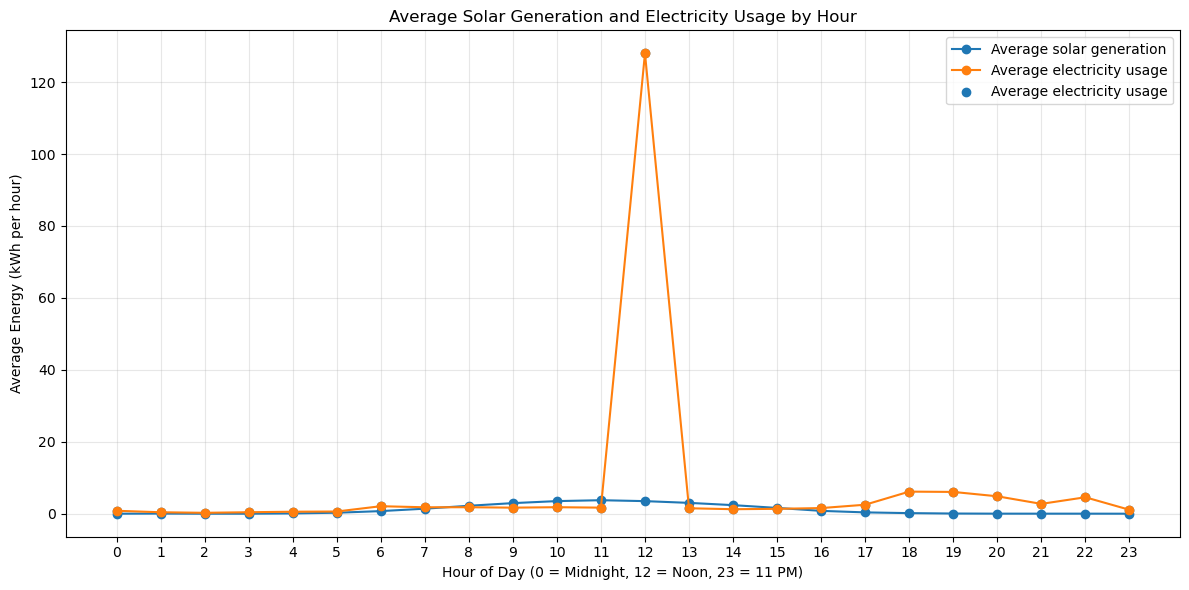

In [26]:
import matplotlib.pyplot as plt
# Extract the hour from each timestamp
df["Hour_of_Day"] = df["Date/hour start"].dt.hour

#average solar generation and usage for each hour
hourly_average = df.groupby("Hour_of_Day")[["Solar electricity generation (kWh)",
     "Electricity usage (kWh)"]].mean()

# Plot both averages on the same chart
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_average.index,
    hourly_average["Solar electricity generation (kWh)"],
    marker="o",
    label="Average solar generation")

plt.plot(
    hourly_average.index,
    hourly_average["Electricity usage (kWh)"],
    marker="o",
    label="Average electricity usage")
plt.scatter(hourly_average.index,
    hourly_average["Electricity usage (kWh)"],
    marker="o",
    label="Average electricity usage")

plt.title("Average Solar Generation and Electricity Usage by Hour")
plt.xlabel("Hour of Day (0 = Midnight, 12 = Noon, 23 = 11 PM)")
plt.ylabel("Average Energy (kWh per hour)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
#proper date/time format
df["Date/hour start"] = pd.to_datetime(df["Date/hour start"],errors="coerce")

In [22]:
print("Start date:", df["Date/hour start"].min())
print("End date:", df["Date/hour start"].max())
print("Total records:", len(df))

Start date: 2020-01-01 00:00:00
End date: 2020-12-31 23:00:00
Total records: 8760


In [23]:
#Electricity readings
#Converting the two columns to numbers
df["Solar electricity generation (kWh)"] = pd.to_numeric(df["Solar electricity generation (kWh)"], errors="coerce")

df["Electricity usage (kWh)"] = pd.to_numeric(df["Electricity usage (kWh)"], errors="coerce")

#Negative readings
print("Negative solar readings:",(df["Solar electricity generation (kWh)"] < 0).sum())

print("Negative electricity usage:",(df["Electricity usage (kWh)"] < 0).sum())

#summary statistics
df[["Solar electricity generation (kWh)","Electricity usage (kWh)"]].describe()

Negative solar readings: 0
Negative electricity usage: 5


,Solar electricity generation (kWh),Electricity usage (kWh)
count,8760.000000,8760.000000
mean,1.116750,7.312704
std,2.026098,491.479806
min,0.000000,-12.624000
25%,0.000000,0.300000
50%,0.024000,0.621000
75%,1.272750,1.686000
max,13.050000,46000.000000


In [10]:
#Checking unusual electricity readings
#Hours around the unusually high reading
date = "2020-01-12 12:00:00"

print("Electricity readings around the selected date:")

df.loc[(df["Date/hour start"] >= pd.Timestamp(date) - pd.Timedelta(hours=3)) & (df["Date/hour start"] <= pd.Timestamp(date) + pd.Timedelta(hours=3)),["Date/hour start", "Hour",
     "Solar electricity generation (kWh)","Electricity usage (kWh)"]]

Electricity readings around the selected date:


,Date/hour start,Hour,Solar electricity generation (kWh),Electricity usage (kWh)
273,2020-01-12 09:00:00,9,0.582,0.690
274,2020-01-12 10:00:00,10,0.951,0.444
275,2020-01-12 11:00:00,11,3.315,0.387
276,2020-01-12 12:00:00,12,5.214,46000.000
277,2020-01-12 13:00:00,13,4.848,0.573
278,2020-01-12 14:00:00,14,0.777,0.459
279,2020-01-12 15:00:00,15,0.411,0.246


In [24]:
#Clean Copy with no outliers
#Clean unusual electricity readings
df_clean = df.copy()

#Keeping the original electricity usage values
df_clean["Original usage (kWh)"] = df_clean["Electricity usage (kWh)"]

#unusually high and negative readings
high_reading = df_clean["Electricity usage (kWh)"] == 46000
negative_reading = df_clean["Electricity usage (kWh)"] < 0

#Why each reading needs checking
df_clean["Data quality flag"] = ""

df_clean.loc[high_reading, "Data quality flag"] = "Unusually high reading"
df_clean.loc[negative_reading, "Data quality flag"] = "Negative reading"

#Replacing flagged readings with missing values
df_clean.loc[high_reading | negative_reading, "Electricity usage (kWh)"] = np.nan

#Filling missing readings using interpolation
df_clean["Electricity usage (kWh)"] = (df_clean["Electricity usage (kWh)"].interpolate())

#Readings that were flagged
display(df_clean[df_clean["Data quality flag"] != ""][["Date/hour start", "Original usage (kWh)","Electricity usage (kWh)", "Data quality flag"]])

print("Flagged readings:", (high_reading | negative_reading).sum())
print("Missing values remaining:", df_clean["Electricity usage (kWh)"].isna().sum())


,Date/hour start,Original usage (kWh),Electricity usage (kWh),Data quality flag
17,2020-01-01 17:00:00,-12.6240,6.017400,Negative reading
276,2020-01-12 12:00:00,46000.0000,0.480000,Unusually high reading
933,2020-02-08 21:00:00,-2.1330,2.776200,Negative reading
935,2020-02-08 23:00:00,-0.2175,1.409944,Negative reading
3593,2020-05-30 17:00:00,-2.5140,1.743300,Negative reading
6464,2020-09-27 08:00:00,-1.9770,4.078500,Negative reading


Flagged readings: 6
Missing values remaining: 0


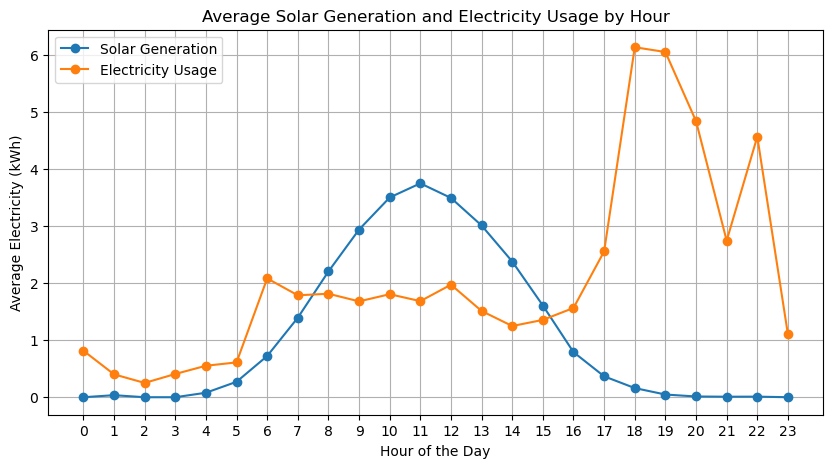

In [28]:
# Comparing average solar generation and electricity usage by hour
hourly_averages = df_clean.groupby("Hour")[["Solar electricity generation (kWh)", "Electricity usage (kWh)"]].mean()

hourly_averages.plot(figsize=(10, 5), marker="o")
plt.title("Average Solar Generation and Electricity Usage by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Electricity (kWh)")
plt.xticks(range(24))
plt.grid(True)
plt.legend(["Solar Generation", "Electricity Usage"])
plt.show()

In [29]:
#Checking the corrected data
print("Original data")
print("Negative readings:", (df["Electricity usage (kWh)"] < 0).sum())
print("Highest usage:", df["Electricity usage (kWh)"].max())

print("Corrected data")
print("Negative readings:", (df_clean["Electricity usage (kWh)"] < 0).sum())
print("Highest usage:", df_clean["Electricity usage (kWh)"].max())
print("Missing values:", df_clean["Electricity usage (kWh)"].isna().sum())

print("Original readings preserved:",(df["Electricity usage (kWh)"] == df_clean["Original usage (kWh)"]).all())

Original data
Negative readings: 5
Highest usage: 46000.0
Corrected data
Negative readings: 0
Highest usage: 61.1028
Missing values: 0
Original readings preserved: True


In [30]:
#Calculate electricity needed without a battery
solar_col = "Solar electricity generation (kWh)"
usage_col = "Electricity usage (kWh)"

#how much electricity must come from the grid
df_clean["Grid purchase without battery (kWh)"] = (df_clean[usage_col] - df_clean[solar_col]).clip(lower=0)

#First 10 records
display(df_clean[["Date/hour start",solar_col,usage_col,"Grid purchase without battery (kWh)"]].head(10))

#Total electricity usage that is solar generation and grid purchases
print("Total electricity usage:", round(df_clean[usage_col].sum(), 2), "kWh")
print("Total solar generation:", round(df_clean[solar_col].sum(), 2), "kWh")
print("Total grid purchases:", round(df_clean["Grid purchase without battery (kWh)"].sum(), 2), "kWh")

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh),Grid purchase without battery (kWh)
0,2020-01-01 00:00:00,0.000,1.509849,1.509849
1,2020-01-01 01:00:00,0.000,1.411859,1.411859
2,2020-01-01 02:00:00,0.000,1.023898,1.023898
3,2020-01-01 03:00:00,0.000,0.642000,0.642000
4,2020-01-01 04:00:00,0.000,0.960000,0.960000
5,2020-01-01 05:00:00,0.012,0.897000,0.885000
6,2020-01-01 06:00:00,0.006,0.648000,0.642000
7,2020-01-01 07:00:00,0.009,0.774000,0.765000
8,2020-01-01 08:00:00,0.012,1.299000,1.287000
9,2020-01-01 09:00:00,0.846,0.606000,0.000000


Total electricity usage: 18095.26 kWh
Total solar generation: 9782.73 kWh
Total grid purchases: 15639.36 kWh


In [31]:
#Part (ii): Grid electricity needed without a battery
solar_col = "Solar electricity generation (kWh)"
usage_col = "Electricity usage (kWh)"

#Electricity needed from the grid
df_clean["Grid purchase without battery (kWh)"] = (df_clean[usage_col] - df_clean[solar_col]).clip(lower=0)

# View the first 10 records
display(df_clean[["Date/hour start",solar_col,usage_col,"Grid purchase without battery (kWh)"]].head(10))

#Total electricity quantities
print("Total electricity usage (kWh):", round(df_clean[usage_col].sum(), 2))
print("Total solar generation (kWh):", round(df_clean[solar_col].sum(), 2))
print("Total grid purchases (kWh):",round(df_clean["Grid purchase without battery (kWh)"].sum(), 2))

#Is there any negative grid purchases?
print("Negative grid purchases:",(df_clean["Grid purchase without battery (kWh)"] < 0).sum())

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh),Grid purchase without battery (kWh)
0,2020-01-01 00:00:00,0.000,1.509849,1.509849
1,2020-01-01 01:00:00,0.000,1.411859,1.411859
2,2020-01-01 02:00:00,0.000,1.023898,1.023898
3,2020-01-01 03:00:00,0.000,0.642000,0.642000
4,2020-01-01 04:00:00,0.000,0.960000,0.960000
5,2020-01-01 05:00:00,0.012,0.897000,0.885000
6,2020-01-01 06:00:00,0.006,0.648000,0.642000
7,2020-01-01 07:00:00,0.009,0.774000,0.765000
8,2020-01-01 08:00:00,0.012,1.299000,1.287000
9,2020-01-01 09:00:00,0.846,0.606000,0.000000


Total electricity usage (kWh): 18095.26
Total solar generation (kWh): 9782.73
Total grid purchases (kWh): 15639.36
Negative grid purchases: 0


In [31]:
#Part (ii): Grid electricity needed without a battery
solar_col = "Solar electricity generation (kWh)"
usage_col = "Electricity usage (kWh)"

#Electricity needed from the grid
df_clean["Grid purchase without battery (kWh)"] = (df_clean[usage_col] - df_clean[solar_col]).clip(lower=0)

# View the first 10 records
display(df_clean[["Date/hour start",solar_col,usage_col,"Grid purchase without battery (kWh)"]].head(10))

#Total electricity quantities
print("Total electricity usage (kWh):", round(df_clean[usage_col].sum(), 2))
print("Total solar generation (kWh):", round(df_clean[solar_col].sum(), 2))
print("Total grid purchases (kWh):",round(df_clean["Grid purchase without battery (kWh)"].sum(), 2))

#Is there any negative grid purchases?
print("Negative grid purchases:",(df_clean["Grid purchase without battery (kWh)"] < 0).sum())

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh),Grid purchase without battery (kWh)
0,2020-01-01 00:00:00,0.000,1.509849,1.509849
1,2020-01-01 01:00:00,0.000,1.411859,1.411859
2,2020-01-01 02:00:00,0.000,1.023898,1.023898
3,2020-01-01 03:00:00,0.000,0.642000,0.642000
4,2020-01-01 04:00:00,0.000,0.960000,0.960000
5,2020-01-01 05:00:00,0.012,0.897000,0.885000
6,2020-01-01 06:00:00,0.006,0.648000,0.642000
7,2020-01-01 07:00:00,0.009,0.774000,0.765000
8,2020-01-01 08:00:00,0.012,1.299000,1.287000
9,2020-01-01 09:00:00,0.846,0.606000,0.000000


Total electricity usage (kWh): 18095.26
Total solar generation (kWh): 9782.73
Total grid purchases (kWh): 15639.36
Negative grid purchases: 0


In [33]:
#Hours with the highest excess solar generation
display(df_clean.nlargest(10, "Excess solar (kWh)")[["Date/hour start","Solar electricity generation (kWh)","Electricity usage (kWh)","Excess solar (kWh)"]])

#hours when solar generation exceeds electricity usage
print("Hours with excess solar:",(df_clean["Excess solar (kWh)"] > 0).sum())

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh),Excess solar (kWh)
2569,2020-04-18 01:00:00,13.050,0.315968,12.734032
3107,2020-05-10 11:00:00,10.998,0.000000,10.998000
3707,2020-06-04 11:00:00,10.359,0.183000,10.176000
4163,2020-06-23 11:00:00,10.152,0.000000,10.152000
4523,2020-07-08 11:00:00,10.383,0.261000,10.122000
3372,2020-05-21 12:00:00,9.957,0.000000,9.957000
4426,2020-07-04 10:00:00,10.518,0.603000,9.915000
3299,2020-05-18 11:00:00,9.873,0.000000,9.873000
2773,2020-04-26 13:00:00,9.912,0.051000,9.861000
3300,2020-05-18 12:00:00,9.732,0.000000,9.732000


Hours with excess solar: 2619


In [34]:
#Hourly battery charge
battery_capacity = 12.5
charge = 0
battery_charge = []

solar = df_clean["Solar electricity generation (kWh)"].to_numpy()
usage = df_clean["Electricity usage (kWh)"].to_numpy()

for i in range(len(df_clean)):
    excess_solar = max(0, solar[i] - usage[i])
    shortfall = max(0, usage[i] - solar[i])

#Charge the battery with excess solar
    if excess_solar > 0:
        charge = min(battery_capacity, charge + excess_solar)

#Use battery energy when solar is not enough
    else:
        charge = max(0, charge - shortfall)
    battery_charge.append(charge)

df_clean["Battery charge (kWh)"] = battery_charge

#See the first 15 hours
display(df_clean[[
    "Date/hour start",
    "Solar electricity generation (kWh)",
    "Electricity usage (kWh)",
    "Excess solar (kWh)",
    "Battery charge (kWh)"
]].head(15))

#Battery charge limits
print("Minimum charge:", df_clean["Battery charge (kWh)"].min(), "kWh")
print("Maximum charge:", df_clean["Battery charge (kWh)"].max(), "kWh")
print("Battery capacity:", battery_capacity, "kWh")

print("Outside battery limits:",
      ((df_clean["Battery charge (kWh)"] < 0) |
       (df_clean["Battery charge (kWh)"] > battery_capacity)).any())

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh),Excess solar (kWh),Battery charge (kWh)
0,2020-01-01 00:00:00,0.000,1.509849,0.000,0.000
1,2020-01-01 01:00:00,0.000,1.411859,0.000,0.000
2,2020-01-01 02:00:00,0.000,1.023898,0.000,0.000
3,2020-01-01 03:00:00,0.000,0.642000,0.000,0.000
4,2020-01-01 04:00:00,0.000,0.960000,0.000,0.000
5,2020-01-01 05:00:00,0.012,0.897000,0.000,0.000
6,2020-01-01 06:00:00,0.006,0.648000,0.000,0.000
7,2020-01-01 07:00:00,0.009,0.774000,0.000,0.000
8,2020-01-01 08:00:00,0.012,1.299000,0.000,0.000
9,2020-01-01 09:00:00,0.846,0.606000,0.240,0.240


Minimum charge: 0.0 kWh
Maximum charge: 12.5 kWh
Battery capacity: 12.5 kWh
Outside battery limits: False


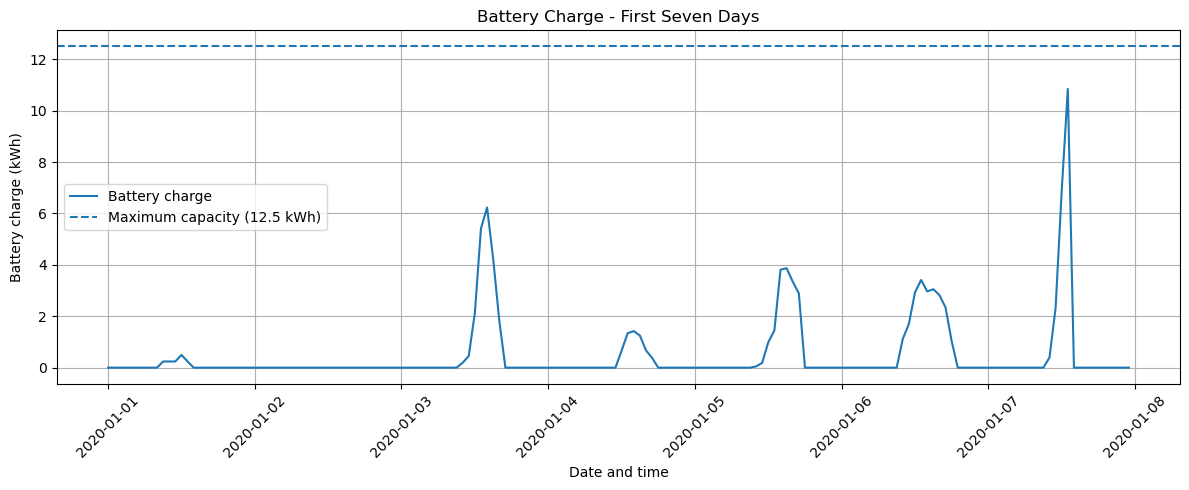

In [35]:
#Plot battery charge for the first seven days
first_week = df_clean.head(168)

plt.figure(figsize=(12, 5))
plt.plot(first_week["Date/hour start"], first_week["Battery charge (kWh)"],label="Battery charge")

plt.axhline(battery_capacity, linestyle="--",label="Maximum capacity (12.5 kWh)")

plt.title("Battery Charge - First Seven Days")
plt.xlabel("Date and time")
plt.ylabel("Battery charge (kWh)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
#Part (v):hourly grid purchases with the battery
solar_col = "Solar electricity generation (kWh)"
usage_col = "Electricity usage (kWh)"

solar = df_clean[solar_col].to_numpy()
usage = df_clean[usage_col].to_numpy()

battery_capacity = 12.5
battery_charge = 0.0

# Storing the hourly results
battery_used_list = []
grid_with_battery_list = []
battery_charge_list = []

for i in range(len(df_clean)):

#The electricity shortage after solar is used
    energy_shortfall = max(0, usage[i] - solar[i])

#Excess solar available to charge the battery
    excess_solar = max(0, solar[i] - usage[i])

    if energy_shortfall > 0:
#Stored battery energy to reducing the shortage
        battery_used = min(battery_charge, energy_shortfall)

#Remaining shortage to be purchased from the grid
        grid_purchase = energy_shortfall - battery_used
#Battery charge after discharging
        battery_charge = battery_charge - battery_used
    else:
#No grid purchase is needed in an hour with a solar surplus
        battery_used = 0.0
        grid_purchase = 0.0

#Store excess solar, without exceeding battery capacity
        battery_charge = min(
            battery_capacity,
            battery_charge + excess_solar)

#Save the hourly results
    battery_used_list.append(battery_used)
    grid_with_battery_list.append(grid_purchase)
    battery_charge_list.append(battery_charge)

#Add results to the analysis dataframe
df_clean["Battery energy used (kWh)"] = battery_used_list
df_clean["Grid purchase with battery (kWh)"] = grid_with_battery_list
df_clean["Battery charge (kWh)"] = battery_charge_list

#Summary of the results
print("Annual grid purchases with battery:",
      round(df_clean["Grid purchase with battery (kWh)"].sum(), 3), "kWh")

print("Annual battery energy used:",
      round(df_clean["Battery energy used (kWh)"].sum(), 3), "kWh")

print("Minimum battery charge:",
      round(df_clean["Battery charge (kWh)"].min(), 3), "kWh")

print("Maximum battery charge:",
      round(df_clean["Battery charge (kWh)"].max(), 3), "kWh")

print("Maximum battery capacity:", battery_capacity, "kWh")

#Display of the first 15 hours
df_clean[[
    "Date/hour start",
    solar_col,
    usage_col,
    "Battery energy used (kWh)",
    "Grid purchase with battery (kWh)",
    "Battery charge (kWh)"
]].head(15)

Annual grid purchases with battery: 12137.1 kWh
Annual battery energy used: 3502.26 kWh
Minimum battery charge: 0.0 kWh
Maximum battery charge: 12.5 kWh
Maximum battery capacity: 12.5 kWh


,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh),Battery energy used (kWh),Grid purchase with battery (kWh),Battery charge (kWh)
0,2020-01-01 00:00:00,0.000,1.509849,0.000,1.509849,0.000
1,2020-01-01 01:00:00,0.000,1.411859,0.000,1.411859,0.000
2,2020-01-01 02:00:00,0.000,1.023898,0.000,1.023898,0.000
3,2020-01-01 03:00:00,0.000,0.642000,0.000,0.642000,0.000
4,2020-01-01 04:00:00,0.000,0.960000,0.000,0.960000,0.000
5,2020-01-01 05:00:00,0.012,0.897000,0.000,0.885000,0.000
6,2020-01-01 06:00:00,0.006,0.648000,0.000,0.642000,0.000
7,2020-01-01 07:00:00,0.009,0.774000,0.000,0.765000,0.000
8,2020-01-01 08:00:00,0.012,1.299000,0.000,1.287000,0.000
9,2020-01-01 09:00:00,0.846,0.606000,0.000,0.000000,0.240


In [37]:
#Part (vi):Annual electricity cost savings
electricity_price = 0.17  #Cost per kWh in USD

#costs with and without the battery
cost_without_battery = df_clean["Grid purchase without battery (kWh)"].sum()*electricity_price
cost_with_battery = df_clean["Grid purchase with battery (kWh)"].sum()*electricity_price

#savings
annual_savings = cost_without_battery - cost_with_battery

if cost_without_battery > 0:
    savings_percentage = (annual_savings/cost_without_battery)*100
else:
    savings_percentage = 0

print(f"Electricity price: ${electricity_price} per kWh")
print(f"Cost without battery: ${cost_without_battery:.2f}")
print(f"Cost with battery: ${cost_with_battery:.2f}")
print(f"Annual savings: ${annual_savings:.2f}")
print(f"Cost reduction: {savings_percentage:.2f}%")

Electricity price: $0.17 per kWh
Cost without battery: $2658.69
Cost with battery: $2063.31
Annual savings: $595.38
Cost reduction: 22.39%


In [38]:
# Part (vii): Summarise electricity use by month
df_clean["Month"] = df_clean["Date/hour start"].dt.month

#monthly totals
monthly_summary = df_clean.groupby("Month").agg({
    "Solar electricity generation (kWh)": "sum",
    "Electricity usage (kWh)": "sum",
    "Grid purchase without battery (kWh)": "sum",
    "Grid purchase with battery (kWh)": "sum"
}).reset_index()

#Converting month numbers to names
monthly_summary["Month"] = pd.to_datetime(monthly_summary["Month"], format="%m").dt.strftime("%B")

# Calculate electricity saved
monthly_summary["Grid electricity saved (kWh)"] = (
    monthly_summary["Grid purchase without battery (kWh)"]
    - monthly_summary["Grid purchase with battery (kWh)"]
)
#results
monthly_summary.round(2)

,Month,Solar electricity generation (kWh),Electricity usage (kWh),Grid purchase without battery (kWh),Grid purchase with battery (kWh),Grid electricity saved (kWh)
0,January,266.26,1724.30,1605.61,1469.19,136.43
1,February,449.63,1564.12,1396.99,1195.10,201.89
2,March,602.45,1797.86,1619.01,1384.85,234.16
3,April,915.13,1726.36,1460.50,1144.12,316.38
4,May,1641.36,948.06,717.89,339.93,377.96
5,June,1408.29,1159.00,844.78,447.59,397.19
6,July,1371.46,1196.96,907.45,470.63,436.82
7,August,1158.64,1491.53,1217.89,792.62,425.26
8,September,835.68,1626.77,1402.20,1044.20,358.00
9,October,546.13,1420.75,1260.34,967.35,292.98


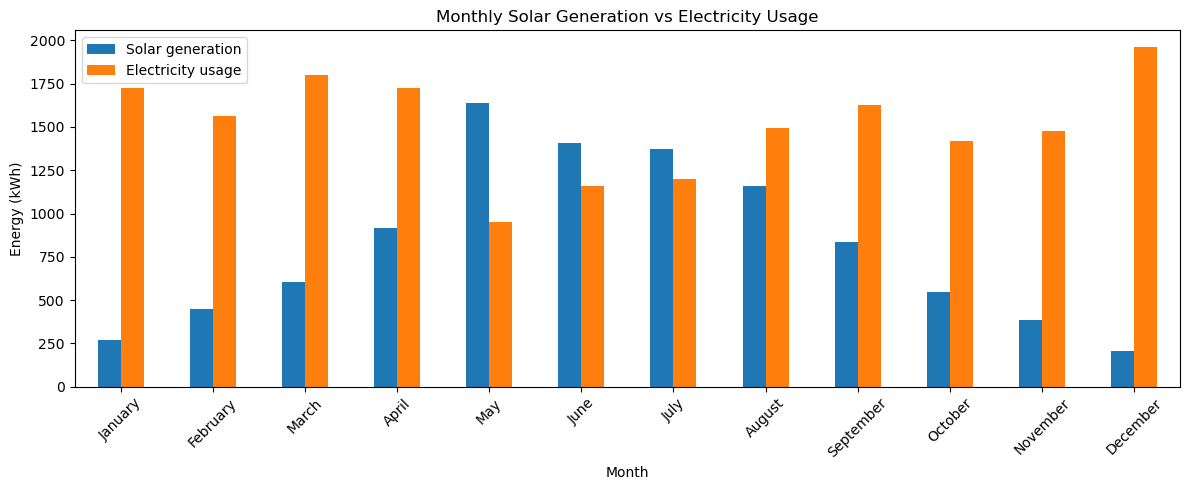

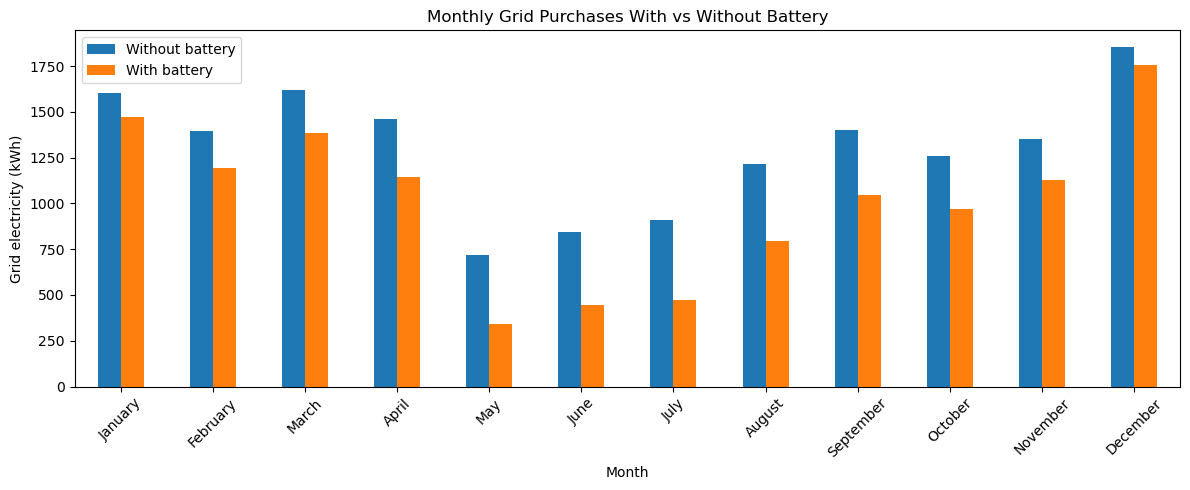

In [39]:
#Monthly Comparision
# Plot monthly solar generation and electricity usage

monthly_plot = monthly_summary.set_index("Month")

monthly_plot[[
    "Solar electricity generation (kWh)",
    "Electricity usage (kWh)"
]].plot(kind="bar", figsize=(12, 5))

plt.title("Monthly Solar Generation vs Electricity Usage")
plt.xlabel("Month")
plt.ylabel("Energy (kWh)")
plt.xticks(rotation=45)
plt.legend(["Solar generation", "Electricity usage"])
plt.tight_layout()
plt.show()


# Plot grid purchases with and without the battery
monthly_plot[[
    "Grid purchase without battery (kWh)",
    "Grid purchase with battery (kWh)"
]].plot(kind="bar", figsize=(12, 5))

plt.title("Monthly Grid Purchases With vs Without Battery")
plt.xlabel("Month")
plt.ylabel("Grid electricity (kWh)")
plt.xticks(rotation=45)
plt.legend(["Without battery", "With battery"])
plt.tight_layout()
plt.show()

In [ ]:
#validations
# Check monthly grid electricity savings

monthly_summary["Recalculated savings (kWh)"] = (
    monthly_summary["Grid purchase without battery (kWh)"]
    - monthly_summary["Grid purchase with battery (kWh)"]
)

monthly_summary["Savings difference (kWh)"] = (
    monthly_summary["Grid electricity saved (kWh)"]
    - monthly_summary["Recalculated savings (kWh)"]
)

#monthly results
display(monthly_summary[[
    "Month",
    "Grid purchase without battery (kWh)",
    "Grid purchase with battery (kWh)",
    "Grid electricity saved (kWh)",
    "Recalculated savings (kWh)",
    "Savings difference (kWh)"
]].round(3))


#Annual totals
grid_without = df_clean["Grid purchase without battery (kWh)"].sum()
grid_with = df_clean["Grid purchase with battery (kWh)"].sum()

print("Annual grid purchases without battery:", round(grid_without, 3), "kWh")
print("Annual grid purchases with battery:", round(grid_with, 3), "kWh")
print("Annual grid electricity saved:", round(grid_without - grid_with, 3), "kWh")

,Month,Grid purchase without battery (kWh),Grid purchase with battery (kWh),Grid electricity saved (kWh),Recalculated savings (kWh),Savings difference (kWh)
0,January,1605.613,1469.187,136.426,136.426,0.0
1,February,1396.988,1195.097,201.891,201.891,0.0
2,March,1619.011,1384.846,234.165,234.165,0.0
3,April,1460.505,1144.121,316.384,316.384,0.0
4,May,717.892,339.930,377.962,377.962,0.0
5,June,844.785,447.593,397.191,397.191,0.0
6,July,907.445,470.627,436.818,436.818,0.0
7,August,1217.886,792.622,425.264,425.264,0.0
8,September,1402.196,1044.200,357.996,357.996,0.0
9,October,1260.336,967.353,292.982,292.982,0.0


Annual grid purchases without battery: 15639.36 kWh
Annual grid purchases with battery: 12137.1 kWh
Annual grid electricity saved: 3502.26 kWh


In [41]:
# Part (viii): 20-Year Discounted Cash Flow (DCF) Model
#Investment assumptions
battery_cost = 7000
battery_life = 20
discount_rate = 0.06
electricity_price = 0.17

#Annual electricity and financial savings
annual_energy_saving = (df_clean["Grid purchase without battery (kWh)"].sum() - df_clean["Grid purchase with battery (kWh)"].sum())

baseline_annual_saving = annual_energy_saving * electricity_price

#table for 20 years
years = np.arange(1, battery_life + 1)
projection = pd.DataFrame({"Year": years})

# Scenario 1: Electricity prices grow by 4% every year
projection["Scenario_1_Annual_Savings_USD"] = (
    baseline_annual_saving * (1.04 ** (projection["Year"] - 1)))

# Scenario 2: Price growth increases by 0.25 percentage points each year
growth_rates = 0.04 + 0.0025 * (projection["Year"] - 1)

# Calculate annual savings under Scenario 2
factors = []
factor = 1.0

for year in years:
    factors.append(factor)
    factor *= 1 + 0.04 + 0.0025 * year

projection["Scenario_2_Annual_Savings_USD"] = (baseline_annual_saving * np.array(factors))

# Calculate the present value of future savings
projection["Discount_Factor"] = ( 1 / (1 + discount_rate) ** projection["Year"])

projection["Scenario_1_PV_USD"] = (projection["Scenario_1_Annual_Savings_USD"] * projection["Discount_Factor"])

projection["Scenario_2_PV_USD"] = (projection["Scenario_2_Annual_Savings_USD"]* projection["Discount_Factor"])
                                   
display(projection.round(2))

#total savings and net present value (NPV)
print("Annual energy saving:", round(annual_energy_saving, 2), "kWh")
print("Annual financial saving: $", round(baseline_annual_saving, 2))

print("\nScenario 1: 4% annual price growth")
print("Total savings: $", round(projection["Scenario_1_Annual_Savings_USD"].sum(), 2))
print("NPV after battery cost: $", round(projection["Scenario_1_PV_USD"].sum() - battery_cost, 2))

print("\nScenario 2: Increasing price growth")
print("Total savings: $", round(projection["Scenario_2_Annual_Savings_USD"].sum(), 2))
print("NPV after battery cost: $", round(projection["Scenario_2_PV_USD"].sum() - battery_cost, 2))

,Year,Scenario_1_Annual_Savings_USD,Scenario_2_Annual_Savings_USD,Discount_Factor,Scenario_1_PV_USD,Scenario_2_PV_USD
0,1,595.38,595.38,0.94,561.68,561.68
1,2,619.20,620.69,0.89,551.09,552.41
2,3,643.97,648.62,0.84,540.69,544.59
3,4,669.73,679.43,0.79,530.49,538.17
4,5,696.52,713.40,0.75,520.48,533.09
5,6,724.38,750.85,0.70,510.66,529.32
6,7,753.35,792.15,0.67,501.02,526.83
7,8,783.48,837.70,0.63,491.57,525.58
8,9,814.82,887.96,0.59,482.29,525.58
9,10,847.42,943.46,0.56,473.19,526.82


Annual energy saving: 3502.26 kWh
Annual financial saving: $ 595.38

Scenario 1: 4% annual price growth
Total savings: $ 17729.4
NPV after battery cost: $ 2430.81

Scenario 2: Increasing price growth
Total savings: $ 21656.6
NPV after battery cost: $ 3989.14


In [47]:
# Part (ix): Calculate the Internal Rate of Return (IRR)
# Adding the initial battery cost and the 20 years of savings
cashflows_1 = np.concatenate(([-battery_cost], projection["Scenario_1_Annual_Savings_USD"].to_numpy()))

cashflows_2 = np.concatenate(([-battery_cost],projection["Scenario_2_Annual_Savings_USD"].to_numpy()))

# Net present value (NPV)
def calculate_npv(rate, cashflows):
    years = np.arange(len(cashflows))
    return np.sum(cashflows / (1 + rate) ** years)

# IRR by testing different rates
def calculate_irr(cashflows):
    low = -0.99
    high = 1.0

    for _ in range(200):
        rate = (low + high) / 2
        npv = calculate_npv(rate, cashflows)

        # Stop when NPV is close to zero
        if abs(npv) < 0.000001:
            return rate

        # Adjust the rate based on the NPV
        if npv > 0:
            low = rate
        else:
            high = rate

    return (low + high) / 2

# IRR for both scenarios
irr_1 = calculate_irr(cashflows_1)
irr_2 = calculate_irr(cashflows_2)

print("Scenario 1: 4% annual price growth")
print("IRR:", round(irr_1 * 100, 2), "%")
print("NPV at 6% discount rate:", round(calculate_npv(0.06, cashflows_1), 2))

print("\nScenario 2: Increasing annual price growth")
print("IRR:", round(irr_2 * 100, 2), "%")
print("NPV at 6% discount rate:", round(calculate_npv(0.06, cashflows_2), 2))

Scenario 1: 4% annual price growth
IRR: 9.43 %
NPV at 6% discount rate: 2430.81

Scenario 2: Increasing annual price growth
IRR: 10.95 %
NPV at 6% discount rate: 3989.14


In [48]:
#Running one more data quality check since a found a solar reading of 13.05 kWh at 01:00 on 18 April 2020
df_clean["Hour_of_Day"] = df_clean["Date/hour start"].dt.hour

#Find records with solar generation between midnight and 4 AM
night_solar = df_clean[(df_clean["Hour_of_Day"].isin([0, 1, 2, 3, 4]))
    & (df_clean["Solar electricity generation (kWh)"] > 0)]

#largest nighttime readings first
night_solar = night_solar.sort_values(
    "Solar electricity generation (kWh)", ascending=False)

#20 records for investigation
display(night_solar[[
    "Date/hour start",
    "Solar electricity generation (kWh)",
    "Electricity usage (kWh)"
]].head(20))

print("Nighttime solar records:", len(night_solar))

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh)
2569,2020-04-18 01:00:00,13.050,0.315968
1516,2020-03-05 04:00:00,1.392,0.489000
1612,2020-03-09 04:00:00,0.951,0.978000
1636,2020-03-10 04:00:00,0.879,3.410000
4396,2020-07-03 04:00:00,0.879,0.306000
3676,2020-06-03 04:00:00,0.786,0.255000
4420,2020-07-04 04:00:00,0.726,0.333000
1540,2020-03-06 04:00:00,0.615,0.933000
4084,2020-06-20 04:00:00,0.606,0.267000
3988,2020-06-16 04:00:00,0.603,0.480000


Nighttime solar records: 239


,count,mean,median,max
Hour_of_Day,,,,
0,365,0.000,0.000,0.000
1,365,0.036,0.000,13.050
2,365,0.000,0.000,0.000
3,365,0.000,0.000,0.000
4,365,0.079,0.006,1.392
5,365,0.271,0.015,5.001
6,365,0.723,0.216,5.928
7,365,1.395,0.624,6.198
8,365,2.206,1.419,7.860


Positive nighttime readings: 571
Total nighttime solar generation: 140.502 kWh


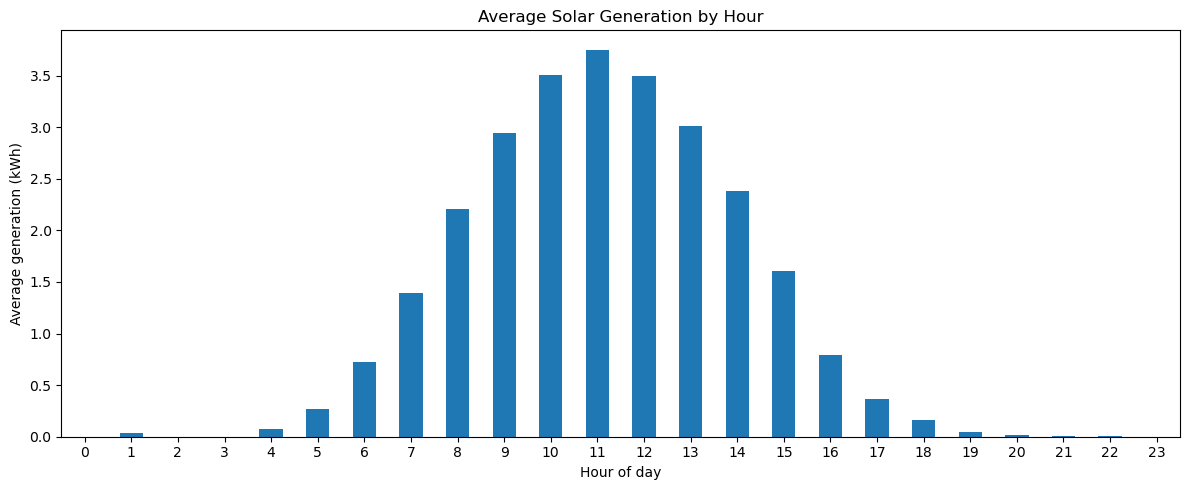

In [49]:
#The 239 records should be deleted since some readings may reflect a timestamp problem, a time-zone issue, or a source-data problem. We need to establish what is happening before correcting them
#Investigate solar generation by hour
solar_col = "Solar electricity generation (kWh)"

#Number of readings and solar generation statistics for each hour
solar_by_hour = df_clean.groupby("Hour_of_Day")[solar_col].agg(
    ["count", "mean", "median", "max"]).round(3)

#hourly summary
display(solar_by_hour)

#Solar generation between midnight and 5 AM
night_check = df_clean[
    (df_clean["Hour_of_Day"].between(0, 5))
    & (df_clean[solar_col] > 0)]

#Number and total of nighttime readings
print("Positive nighttime readings:", len(night_check))
print("Total nighttime solar generation:",
      round(night_check[solar_col].sum(), 3), "kWh")

#Plot average solar generation for each hour
solar_by_hour["mean"].plot(kind="bar", figsize=(12, 5))

plt.title("Average Solar Generation by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average generation (kWh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [50]:
# Find unusually high solar readings between midnight and 5 AM
suspicious_solar = df_clean[
    (df_clean["Hour_of_Day"].between(0, 5)) &
    (df_clean[solar_col] > 1)
].sort_values(by=solar_col, ascending=False)

#Readings for investigation
display(suspicious_solar[[
    "Date/hour start",
    solar_col,
    usage_col
]])

#unusual readings
print("Suspicious early-morning readings:", len(suspicious_solar))

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh)
2569,2020-04-18 01:00:00,13.050,0.315968
1589,2020-03-08 05:00:00,5.001,0.132000
3677,2020-06-03 05:00:00,2.496,0.126000
1493,2020-03-04 05:00:00,2.313,0.516000
3989,2020-06-16 05:00:00,2.142,0.330000
1517,2020-03-05 05:00:00,2.079,0.516000
3917,2020-06-13 05:00:00,1.935,0.321000
4229,2020-06-26 05:00:00,1.899,6.726000
3701,2020-06-04 05:00:00,1.881,0.222000
3893,2020-06-12 05:00:00,1.866,0.312000


Suspicious early-morning readings: 40


In [ ]:
# Flagging suspected solar anomaly without changing the original reading

# A column for data-quality notes
df_clean["Solar data quality flag"] = ""

#date and time to review
anomaly_time = pd.Timestamp("2020-04-18 01:00:00")

#record for investigation
df_clean.loc[
    df_clean["Date/hour start"] == anomaly_time,
    "Solar data quality flag"
] = "Review: suspected overnight solar spike"

#Display the flagged record
display(df_clean.loc[
    df_clean["Date/hour start"] == anomaly_time,
    ["Date/hour start", solar_col, usage_col, "Solar data quality flag"]
])

,Date/hour start,Solar electricity generation (kWh),Electricity usage (kWh),Solar data quality flag
2569,2020-04-18 01:00:00,13.05,0.315968,Review: suspected overnight solar spike


In [51]:
#Sensitivity analysis
#A copy for sensitivity testing
df_sensitivity = df_clean.copy()

# Identify the suspected solar anomaly
anomaly_time = pd.Timestamp("2020-04-18 01:00:00")

# Set the reading to zero in the copy only
df_sensitivity.loc[df_sensitivity["Date/hour start"] == anomaly_time,solar_col] = 0

#Comparision between total solar generation before and after the change
original_total = df_clean[solar_col].sum()
adjusted_total = df_sensitivity[solar_col].sum()

#results
print("Original solar generation:", round(original_total, 3), "kWh")
print("Sensitivity test total:", round(adjusted_total, 3), "kWh")
print("Difference:", round(original_total - adjusted_total, 3), "kWh")

Original solar generation: 9782.727 kWh
Sensitivity test total: 9769.677 kWh
Difference: 13.05 kWh


In [52]:
#compare grid purchases and savings
# Recalculate grid purchases using the sensitivity dataset
# Get solar generation and electricity usage
solar = df_sensitivity[solar_col].to_numpy()
usage = df_sensitivity[usage_col].to_numpy()

# Set the battery capacity and starting charge
battery_capacity = 12.5
battery_charge = 0

# Calculate grid purchases without a battery
grid_without_battery = np.maximum(0, usage - solar)

# Store grid purchases when using the battery
grid_with_battery = []

for i in range(len(solar)):

    # Calculate the electricity shortage and extra solar energy
    shortage = max(0, usage[i] - solar[i])
    surplus = max(0, solar[i] - usage[i])

    # Use the battery to cover any shortage
    battery_used = min(battery_charge, shortage)
    grid_purchase = shortage - battery_used
    battery_charge -= battery_used

    # Charge the battery when solar energy is in surplus
    if shortage == 0:
        battery_charge = min(battery_capacity, battery_charge + surplus)

    # Save the grid purchase for this hour
    grid_with_battery.append(grid_purchase)

# Calculate annual energy and financial savings
energy_saved = grid_without_battery.sum() - sum(grid_with_battery)
financial_savings = energy_saved * 0.17

# Display the results
print("Grid purchases without battery:", round(grid_without_battery.sum(), 3), "kWh")
print("Grid purchases with battery:", round(sum(grid_with_battery), 3), "kWh")
print("Annual energy saved:", round(energy_saved, 3), "kWh")
print("Annual financial savings: $", round(financial_savings, 2))

Grid purchases without battery: 15639.676 kWh
Grid purchases with battery: 12140.597 kWh
Annual energy saved: 3499.079 kWh
Annual financial savings: $ 594.84


In [ ]:
#Inspect the projection table
# Display savings for the first five years and the final year
display(projection[
    projection["Year"].isin([1, 2, 3, 4, 5, 20])
][[
    "Year",
    "Scenario_1_Annual_Savings_USD",
    "Scenario_2_Annual_Savings_USD",
    "Discount_Factor",
    "Scenario_1_PV_USD",
    "Scenario_2_PV_USD"
]].round(2))

,Year,Scenario_1_Annual_Savings_USD,Scenario_2_Annual_Savings_USD,Discount_Factor,Scenario_1_PV_USD,Scenario_2_PV_USD
0,1,595.38,595.38,0.94,561.68,561.68
1,2,619.20,620.69,0.89,551.09,552.41
2,3,643.97,648.62,0.84,540.69,544.59
3,4,669.73,679.43,0.79,530.49,538.17
4,5,696.52,713.40,0.75,520.48,533.09
19,20,1254.38,1966.79,0.31,391.12,613.25


In [53]:
#Correct and Validate the projection
# Rebuild the 20-year electricity savings projection
battery_cost = 7000
discount_rate = 0.06
baseline_annual_saving = 595.38

years = np.arange(1, 21)
projection_check = pd.DataFrame({"Year": years})

# Scenario 1: Electricity prices grow by 4% each year
projection_check["Scenario 1 Savings ($)"] = (
    baseline_annual_saving * 1.04 ** (years - 1))

# Scenario 2: Annual growth increases by 0.25 percentage points
factors = []
factor = 1

for year in years:
    factors.append(factor)
    factor *= 1 + 0.04 + 0.0025 * year

projection_check["Scenario 2 Savings ($)"] = (
    baseline_annual_saving * np.array(factors))

# Calculate present value of each year's savings
projection_check["Discount Factor"] = (
    1 / (1 + discount_rate) ** years)

projection_check["Scenario 1 Present Value ($)"] = (
    projection_check["Scenario 1 Savings ($)"]
    * projection_check["Discount Factor"])

projection_check["Scenario 2 Present Value ($)"] = (
    projection_check["Scenario 2 Savings ($)"]
    * projection_check["Discount Factor"])

# Display Years 1–5 and Year 20
display(
    projection_check[
        projection_check["Year"].isin([1, 2, 3, 4, 5, 20])
    ].round(2))

,Year,Scenario 1 Savings ($),Scenario 2 Savings ($),Discount Factor,Scenario 1 Present Value ($),Scenario 2 Present Value ($)
0,1,595.38,595.38,0.94,561.68,561.68
1,2,619.20,620.68,0.89,551.08,552.41
2,3,643.96,648.61,0.84,540.68,544.59
3,4,669.72,679.42,0.79,530.48,538.17
4,5,696.51,713.39,0.75,520.47,533.09
19,20,1254.38,1966.77,0.31,391.12,613.25


In [59]:
#Calculate investment return
# Calculate total savings over 20 years
scenario_1_total_savings = projection_check["Scenario 1 Savings ($)"].sum()
scenario_2_total_savings = projection_check["Scenario 2 Savings ($)"].sum()

# Calculate net present value (NPV)
# NPV = present value of future savings - initial battery cost
scenario_1_npv = projection_check["Scenario 1 Present Value ($)"].sum() - battery_cost
scenario_2_npv = projection_check["Scenario 2 Present Value ($)"].sum() - battery_cost

# Display results for Scenario 1
print("SCENARIO 1: Electricity prices grow by 4% yearly")
print("Total 20-year savings: $", round(scenario_1_total_savings, 2))
print("NPV after battery cost: $", round(scenario_1_npv, 2))

# Display results for Scenario 2
print("\nSCENARIO 2: Electricity price growth increases each year")
print("Total 20-year savings: $", round(scenario_2_total_savings, 2))
print("NPV after battery cost: $", round(scenario_2_npv, 2))

SCENARIO 1: Electricity prices grow by 4% yearly
Total 20-year savings: $ 17729.27
NPV after battery cost: $ 2430.74

SCENARIO 2: Electricity price growth increases each year
Total 20-year savings: $ 21656.45
NPV after battery cost: $ 3989.06


In [57]:
# Create cash flows, starting with the $7,000 battery investment
scenario_1_cashflows = np.concatenate(([-battery_cost],projection_check["Scenario 1 Savings ($)"].to_numpy()))

scenario_2_cashflows = np.concatenate(([-battery_cost],projection_check["Scenario 2 Savings ($)"].to_numpy()))

# Calculate the internal rate of return (IRR)
scenario_1_irr = calculate_irr(scenario_1_cashflows)
scenario_2_irr = calculate_irr(scenario_2_cashflows)

# Display IRR as a percentage
print("SCENARIO 1: IRR =", round(scenario_1_irr * 100, 2), "%")
print("SCENARIO 2: IRR =", round(scenario_2_irr * 100, 2), "%")

SCENARIO 1: IRR = 9.43 %
SCENARIO 2: IRR = 10.95 %


In [61]:
# Sensitivity analysis: set the suspected solar anomaly to zero

#annual savings
sensitivity_baseline_saving = 3499.079 * 0.17

#20-year projection
sensitivity_projection = pd.DataFrame({"Year": years})

# Scenario 1: Electricity prices increase by 4% annually
sensitivity_projection["Scenario 1 Savings"] = (sensitivity_baseline_saving * 1.04 ** (years - 1))

# Scenario 2: Growth starts at 4% in 2023, then rises by 0.25% each year
rates = np.array([0.04 + 0.0025 * i for i in range(19)])
factors = np.concatenate(([1], np.cumprod(1 + rates)))

sensitivity_projection["Scenario 2 Savings"] = (sensitivity_baseline_saving * factors)

# Calculate present value of savings
sensitivity_projection["Discount Factor"] = (1 / (1 + discount_rate) ** years)

sensitivity_projection["Scenario 1 PV"] = (sensitivity_projection["Scenario 1 Savings"] * sensitivity_projection["Discount Factor"])

sensitivity_projection["Scenario 2 PV"] = (sensitivity_projection["Scenario 2 Savings"] * sensitivity_projection["Discount Factor"])

#NPV
npv_1 = sensitivity_projection["Scenario 1 PV"].sum() - battery_cost
npv_2 = sensitivity_projection["Scenario 2 PV"].sum() - battery_cost

# IRR, including the initial investment
cashflows_1 = np.concatenate(([-battery_cost], sensitivity_projection["Scenario 1 Savings"].to_numpy()))

cashflows_2 = np.concatenate(([-battery_cost], sensitivity_projection["Scenario 2 Savings"].to_numpy()))

irr_1 = calculate_irr(cashflows_1)
irr_2 = calculate_irr(cashflows_2)

print("SENSITIVITY ANALYSIS: SOLAR ANOMALY SET TO ZERO")
print(f"Annual savings: ${sensitivity_baseline_saving:,.2f}")
print(f"Scenario 1 NPV: ${npv_1:,.2f}")
print(f"Scenario 1 IRR: {irr_1:.2%}")
print(f"Scenario 2 NPV: ${npv_2:,.2f}")
print(f"Scenario 2 IRR: {irr_2:.2%}")


SENSITIVITY ANALYSIS: SOLAR ANOMALY SET TO ZERO
Annual savings: $594.84
Scenario 1 NPV: $2,422.24
Scenario 1 IRR: 9.42%
Scenario 2 NPV: $3,732.04
Scenario 2 IRR: 10.71%


In [ ]:
# Compare the annual inflation assumptions for both scenarios
inflation_check = pd.DataFrame({
    "Projection Year": range(1, 21),
    "Calendar Year": range(2022, 2042),

    # Scenario 1: Inflation stays at 4% each year
    "Scenario 1 Inflation": [0.04] * 20,

    # Scenario 2: Inflation increases by 0.25 percentage points yearly
    "Scenario 2 Inflation": [
        0.04 + 0.0025 * year for year in range(20)
    ]
})

# Show the first five and last three years
display(inflation_check.head().round(4))
display(inflation_check.tail(3).round(4))

,Projection Year,Calendar Year,Scenario 1 Inflation,Scenario 2 Inflation
0,1,2022,0.04,0.0400
1,2,2023,0.04,0.0425
2,3,2024,0.04,0.0450
3,4,2025,0.04,0.0475
4,5,2026,0.04,0.0500


,Projection Year,Calendar Year,Scenario 1 Inflation,Scenario 2 Inflation
17,18,2039,0.04,0.0825
18,19,2040,0.04,0.0850
19,20,2041,0.04,0.0875


In [ ]:
print(projection_check.columns.tolist())

['Year', 'Scenario 1 Savings ($)', 'Scenario 2 Savings ($)', 'Discount Factor', 'Scenario 1 Present Value ($)', 'Scenario 2 Present Value ($)']


In [62]:
# Check the projection period
print("Number of projection years:", len(projection_check))
print("First projection year:", projection_check["Year"].min())
print("Last projection year:", projection_check["Year"].max())

# Check the starting annual savings
print("Baseline annual savings: $", round(baseline_annual_saving, 2))

print("Scenario 1 Year 1 savings: $", round(projection_check["Scenario 1 Savings ($)"].iloc[0], 2))

print("Scenario 2 Year 1 savings: $",round(projection_check["Scenario 2 Savings ($)"].iloc[0], 2))

# Check the initial investment in Year 0
print("Scenario 1 initial cash flow: $", scenario_1_cashflows[0])
print("Scenario 2 initial cash flow: $", scenario_2_cashflows[0])

Number of projection years: 20
First projection year: 1
Last projection year: 20
Baseline annual savings: $ 595.38
Scenario 1 Year 1 savings: $ 595.38
Scenario 2 Year 1 savings: $ 595.38
Scenario 1 initial cash flow: $ -7000.0
Scenario 2 initial cash flow: $ -7000.0


In [63]:
# Set up the 20-year projection
years = np.arange(1, 21)

projection_check = pd.DataFrame({"Projection year": years,"Calendar year": years + 2021})

# Scenario 1: Electricity-price growth is 4% from the second projection year
projection_check["Scenario 1 Inflation"] = [ 0 if year == 1 else 0.04 for year in years]

projection_check["Scenario 1 Savings ($)"] = (baseline_annual_saving * 1.04 ** (years - 1))

# Scenario 2: Inflation starts at 4% in the second projection year,
# then increases by 0.25 percentage points each year
scenario_2_factors = [1.0]

for i in range(1, 20):
    growth_rate = 0.04 + 0.0025 * (i - 1)
    scenario_2_factors.append(
        scenario_2_factors[-1] * (1 + growth_rate))

projection_check["Scenario 2 Inflation"] = [
    0 if year == 1 else 0.04 + 0.0025 * (year - 2)
    for year in years]

projection_check["Scenario 2 Savings ($)"] = (
    baseline_annual_saving * np.array(scenario_2_factors))

# Calculate the present value of future savings
projection_check["Discount Factor"] = (1 / (1 + discount_rate) ** years)

projection_check["Scenario 1 PV ($)"] = (projection_check["Scenario 1 Savings ($)"] * projection_check["Discount Factor"])

projection_check["Scenario 2 PV ($)"] = (projection_check["Scenario 2 Savings ($)"] * projection_check["Discount Factor"])

# Add the initial battery cost as a negative Year 0 cash flow
scenario_1_cashflows = np.insert(
    projection_check["Scenario 1 Savings ($)"].to_numpy(),
    0, -battery_cost)

scenario_2_cashflows = np.insert(projection_check["Scenario 2 Savings ($)"].to_numpy(), 0, -battery_cost)

# Calculate total savings, NPV and IRR
scenario_1_total_savings = projection_check["Scenario 1 Savings ($)"].sum()
scenario_2_total_savings = projection_check["Scenario 2 Savings ($)"].sum()

scenario_1_npv = projection_check["Scenario 1 PV ($)"].sum() - battery_cost
scenario_2_npv = projection_check["Scenario 2 PV ($)"].sum() - battery_cost

scenario_1_irr = calculate_irr(scenario_1_cashflows)
scenario_2_irr = calculate_irr(scenario_2_cashflows)

# Show the first five years
display(projection_check.head(5).round(4))

# Compare the investment results
financial_results = pd.DataFrame({
    "Metric": [
        "Initial battery investment ($)",
        "Total 20-year savings ($)",
        "NPV at 6% ($)",
        "IRR (%)"
    ],
    "Scenario 1": [
        -battery_cost,
        scenario_1_total_savings,
        scenario_1_npv,
        scenario_1_irr * 100
    ],
    "Scenario 2": [
        -battery_cost,
        scenario_2_total_savings,
        scenario_2_npv,
        scenario_2_irr * 100
    ]
})

display(financial_results.round(2))

,Projection year,Calendar year,Scenario 1 Inflation,Scenario 1 Savings ($),Scenario 2 Inflation,Scenario 2 Savings ($),Discount Factor,Scenario 1 PV ($),Scenario 2 PV ($)
0,1,2022,0.00,595.3800,0.0000,595.3800,0.9434,561.6792,561.6792
1,2,2023,0.04,619.1952,0.0400,619.1952,0.8900,551.0815,551.0815
2,3,2024,0.04,643.9630,0.0425,645.5110,0.8396,540.6838,541.9835
3,4,2025,0.04,669.7215,0.0450,674.5590,0.7921,530.4822,534.3139
4,5,2026,0.04,696.5104,0.0475,706.6005,0.7473,520.4731,528.0130


,Metric,Scenario 1,Scenario 2
0,Initial battery investment ($),-7000.00,-7000.00
1,Total 20-year savings ($),17729.27,21072.64
2,NPV at 6% ($),2430.74,3741.72
3,IRR (%),9.43,10.72


In [64]:
# FINAL MODEL VALIDATION

# 1. Check the quality of the hourly data
print("Hourly records:", len(df_clean))
print("Missing usage values:", df_clean[usage_col].isna().sum())
print("Negative usage values:", (df_clean[usage_col] < 0).sum())

# 2. Check that grid purchases are reasonable
grid_without_col = "Grid purchase without battery (kWh)"
grid_with_col = "Grid purchase with battery (kWh)"

print("Negative grid purchases without battery:",(df_clean[grid_without_col] < 0).sum())

print("Negative grid purchases with battery:",(df_clean[grid_with_col] < 0).sum())

print("Hours when battery use increases grid purchases:",(df_clean[grid_with_col] > df_clean[grid_without_col] + 1e-8).sum())

# 3. Check that battery charge stays within its capacity
print("Minimum battery charge:",
      round(df_clean["Battery charge (kWh)"].min(), 3), "kWh")

print("Maximum battery charge:", round(df_clean["Battery charge (kWh)"].max(), 3), "kWh")

# 4. Reconcile energy savings and financial savings
grid_without = df_clean[grid_without_col].sum()
grid_with = df_clean[grid_with_col].sum()

energy_saved = grid_without - grid_with
calculated_savings = energy_saved * electricity_price

print("Grid purchases without battery:", round(grid_without, 3), "kWh")
print("Grid purchases with battery:", round(grid_with, 3), "kWh")
print("Grid electricity saved:", round(energy_saved, 3), "kWh")
print("Annual financial savings: $", round(calculated_savings, 2))

# 5. Check the financial projection
print("Projection years:", len(projection_check))
print("First calendar year:", projection_check["Calendar year"].min())
print("Last calendar year:", projection_check["Calendar year"].max())

print("Scenario 1 NPV: $", round(scenario_1_npv, 2))
print("Scenario 2 NPV: $", round(scenario_2_npv, 2))

print("Scenario 1 IRR:", f"{scenario_1_irr:.2%}")
print("Scenario 2 IRR:", f"{scenario_2_irr:.2%}")

Hourly records: 8760
Missing usage values: 0
Negative usage values: 0
Negative grid purchases without battery: 0
Negative grid purchases with battery: 0
Hours when battery use increases grid purchases: 0
Minimum battery charge: 0.0 kWh
Maximum battery charge: 12.5 kWh
Grid purchases without battery: 15639.36 kWh
Grid purchases with battery: 12137.1 kWh
Grid electricity saved: 3502.26 kWh
Annual financial savings: $ 595.38
Projection years: 20
First calendar year: 2022
Last calendar year: 2041
Scenario 1 NPV: $ 2430.74
Scenario 2 NPV: $ 3741.72
Scenario 1 IRR: 9.43%
Scenario 2 IRR: 10.72%


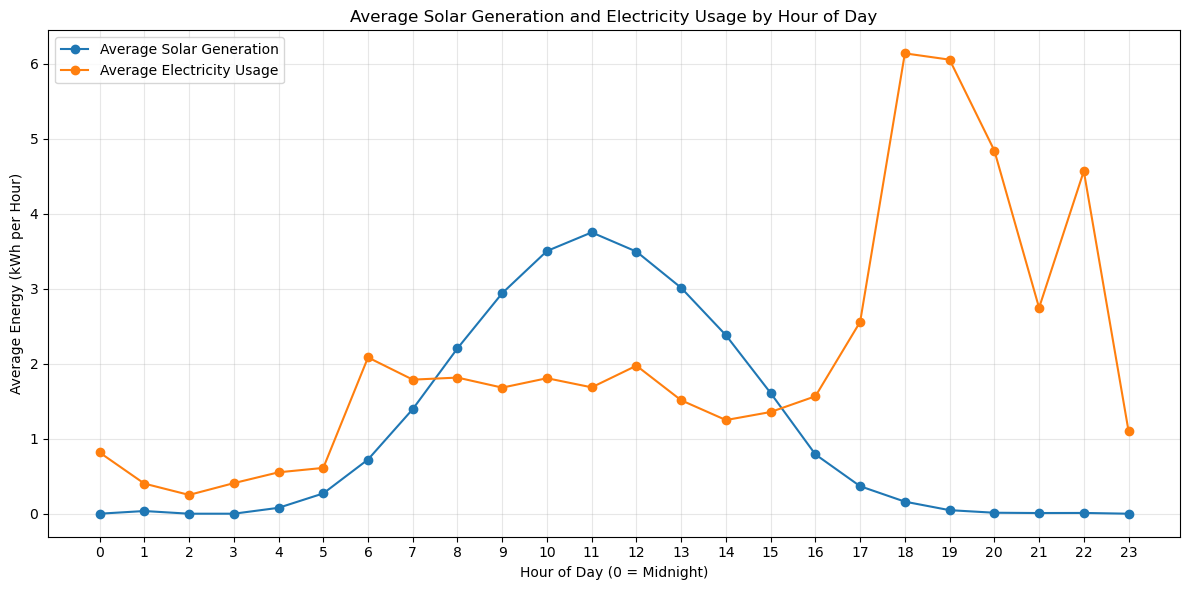

In [65]:
# REQUIRED CHART: Average solar generation and electricity usage by hour

df_clean["Hour_of_Day"] = df_clean["Date/hour start"].dt.hour

hourly_averages = df_clean.groupby("Hour_of_Day")[[solar_col, usage_col]].mean()

ax = hourly_averages.plot(
    kind="line",
    marker="o",
    figsize=(12, 6))

ax.set_title("Average Solar Generation and Electricity Usage by Hour of Day")
ax.set_xlabel("Hour of Day (0 = Midnight)")
ax.set_ylabel("Average Energy (kWh per Hour)")
ax.set_xticks(range(24))
ax.grid(True, alpha=0.3)
ax.legend([
    "Average Solar Generation",
    "Average Electricity Usage"])
plt.tight_layout()
plt.show()

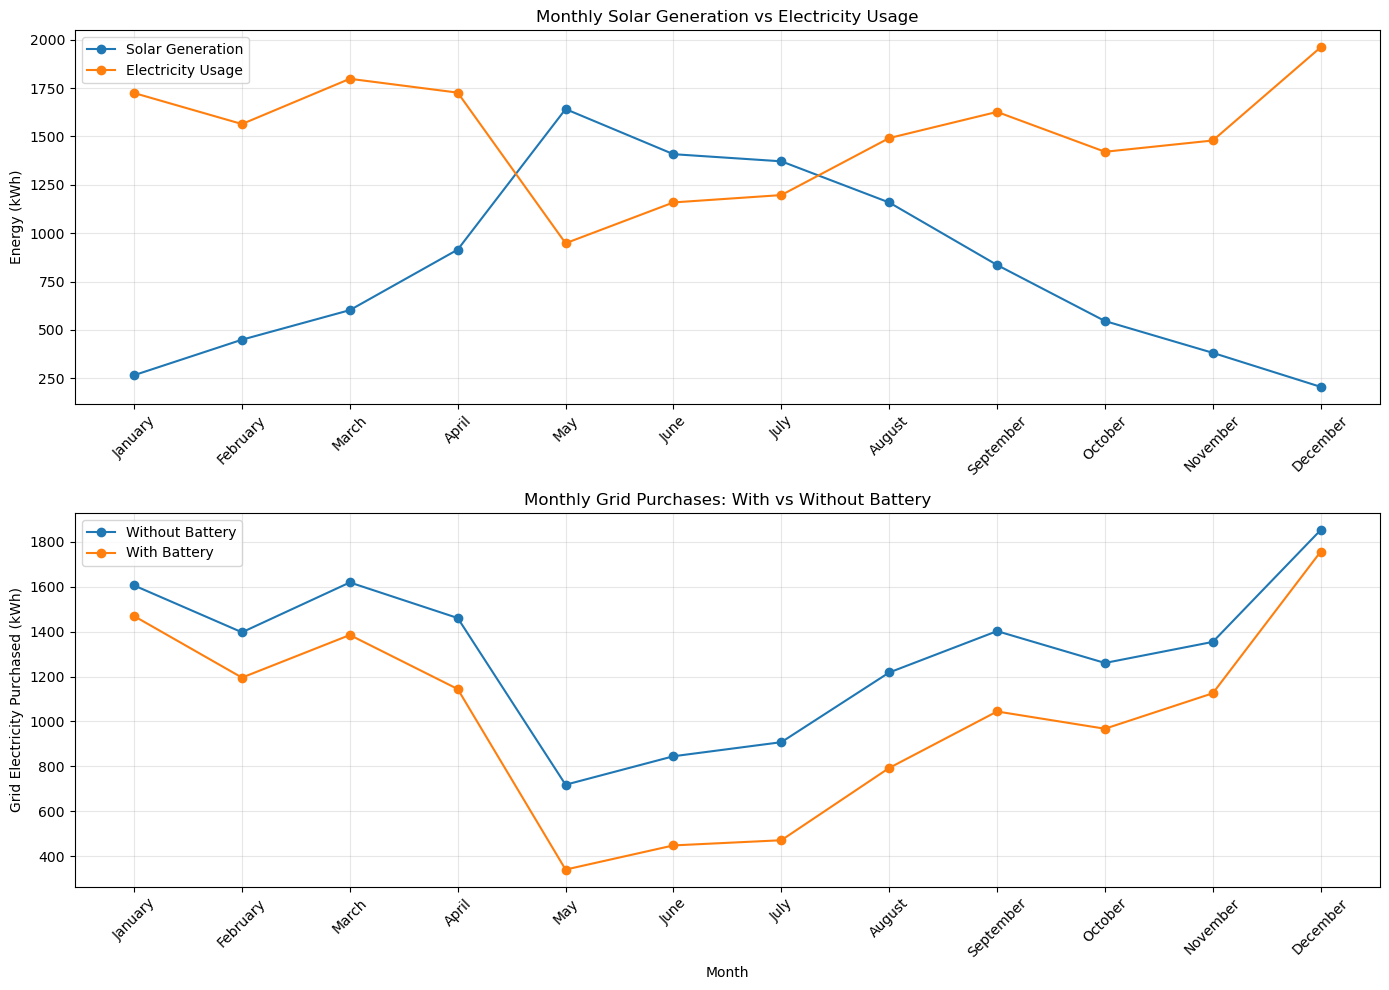

,Month,Solar electricity generation (kWh),Electricity usage (kWh),Grid purchase without battery (kWh),Grid purchase with battery (kWh)
0,January,266.26,1724.30,1605.61,1469.19
1,February,449.63,1564.12,1396.99,1195.10
2,March,602.45,1797.86,1619.01,1384.85
3,April,915.13,1726.36,1460.50,1144.12
4,May,1641.36,948.06,717.89,339.93
5,June,1408.29,1159.00,844.78,447.59
6,July,1371.46,1196.96,907.45,470.63
7,August,1158.64,1491.53,1217.89,792.62
8,September,835.68,1626.77,1402.20,1044.20
9,October,546.13,1420.75,1260.34,967.35


In [66]:
# REQUIRED MONTHLY CHARTS

# Sort the months in calendar order
month_order = ["January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"]

monthly_plot = monthly_summary.copy()

monthly_plot["Month"] = pd.Categorical(
    monthly_plot["Month"],
    categories=month_order,
    ordered=True)

monthly_plot = monthly_plot.sort_values("Month")

# Create two charts
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Chart 1: Solar generation compared with electricity usage
axes[0].plot(
    monthly_plot["Month"].astype(str),
    monthly_plot["Solar electricity generation (kWh)"],
    marker="o",
    label="Solar Generation")

axes[0].plot(
    monthly_plot["Month"].astype(str),
    monthly_plot["Electricity usage (kWh)"],
    marker="o",
    label="Electricity Usage")

axes[0].set_title("Monthly Solar Generation vs Electricity Usage")
axes[0].set_ylabel("Energy (kWh)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis="x", rotation=45)

# Chart 2: Grid purchases with and without the battery
axes[1].plot(
    monthly_plot["Month"].astype(str),
    monthly_plot["Grid purchase without battery (kWh)"],
    marker="o",
    label="Without Battery")

axes[1].plot(
    monthly_plot["Month"].astype(str),
    monthly_plot["Grid purchase with battery (kWh)"],
    marker="o",
    label="With Battery")

axes[1].set_title("Monthly Grid Purchases: With vs Without Battery")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Grid Electricity Purchased (kWh)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Display the monthly summary table
display(monthly_plot[[ "Month",
            "Solar electricity generation (kWh)",
            "Electricity usage (kWh)",
            "Grid purchase without battery (kWh)",
            "Grid purchase with battery (kWh)"]].round(2))